# Task 1: Supervised learning 

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

SEED = 42

def set_seed(seed = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
         torch.cuda.manual_seed_all(seed)

    if torch.backends.cudnn.is_available():
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False


set_seed(SEED)

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))# normal mnist normalization using mean 0.130and std 0.308 of the dataset
])

train_data = datasets.MNIST(root="./data", train=True , download=True, transform=transform)
test_data  = datasets.MNIST(root="./data", train=False, download=True, transform=transform)



100%|██████████| 9.91M/9.91M [00:00<00:00, 18.4MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 488kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.98MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.68MB/s]


### Data split


In [2]:
train_size = int(0.8 * len(train_data))
val_size = len(train_data) - train_size
## the train/validation split is always the same at every run, so
#I can be sure that the same samples are used for training and validation across different experiments, making the results comparable
split_generator = torch.Generator().manual_seed(SEED)


train_subset , val_subset = random_split(train_data, [train_size, val_size], generator = split_generator)

print("Train subset:" , train_size)
print("Validation subset:" , val_size)
print("Test set:" , len(test_data))

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Running on:" , device)


Train subset: 48000
Validation subset: 12000
Test set: 10000
Running on: cuda


In [3]:
class ShallowNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1  = nn.Linear(784,128)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(128,10)

    def forward(self, x):
         x = x.view(x.size(0), -1)
         x = self.fc1(x)
         x = self.relu(x)
         x = self.fc2(x)
         return x


class DeepNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.fc1 = nn.Linear(784, 512)
        self.bn1 = nn.BatchNorm1d(512)
        self.fc2 = nn.Linear(512,256)
        self.bn2 = nn.BatchNorm1d(256)
        self.fc3 = nn.Linear(256, 128)
        self.bn3 = nn.BatchNorm1d(128)
        self.fc4 = nn.Linear(128,10)

        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.3)

    def forward(self, x):
        x = x.view(x.size(0),-1)

        x = self.fc1(x)
        x = self.bn1(x)
        x = self.relu(x)
        x = self.dropout(x)

        x = self.fc2(x)
        x = self.bn2(x)
        x = self.relu(x)
        x = self.dropout(x)

        x = self.fc3(x)
        x = self.bn3(x)
        x = self.relu(x)
        x = self.dropout(x)

        x = self.fc4(x)
        return x


### Training and evaluation functions


In [ ]:
def make_loader(dataset, batch_size, shuffle, seed=SEED):
    gen = None
    if shuffle:
        
        gen = torch.Generator().manual_seed(seed)

    loader = DataLoader(dataset, batch_size=batch_size, shuffle=shuffle, generator=gen)
    return loader


def evaluate(model, loader, criterion):
    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0


    with torch.no_grad():
        for inputs, labels in loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            loss = criterion(outputs, labels)

            bs = labels.size(0)
            total_loss = total_loss + loss.item() * bs

            _, pred = outputs.max(1)
            total = total + bs
            correct = correct + (pred == labels).sum().item()



    avg_loss = total_loss / total
    avg_acc = 100.0 * correct / total


    return avg_loss, avg_acc


def train_model(model, train_loader, val_loader, lr, epochs, weight_decay=0.0):
    model = model.to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

    train_losses = []
    val_losses = []
    train_accs = []
    val_accs = []

    for e in range(epochs):
        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        for inputs, labels in train_loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(inputs)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            bs = labels.size(0)
            running_loss = running_loss+loss.item() * bs

            _, pred =   outputs.max(1)
            total    =   total+bs
            correct =   correct+(pred ==labels).sum().item()

        train_losses.append(running_loss / total)
        train_accs.append(100.0*correct / total)

        if val_loader is not None:
            val_loss, val_acc= evaluate(model, val_loader, criterion)
            val_losses.append(val_loss)
            val_accs.append(val_acc)

    return train_losses,train_accs, val_losses, val_accs


def run_validation_experiment(model_class, batch_size, lr, epochs, weight_decay=0.0, seed=SEED):
    set_seed(seed)

    train_loader = make_loader(train_subset, batch_size=batch_size, shuffle=True, seed=seed)
    val_loader = make_loader(val_subset, batch_size=batch_size, shuffle=False, seed=seed)

    model = model_class()

    train_losses, train_accs, val_losses, val_accs = train_model(
        model,
        train_loader,
        val_loader,
        lr = lr,
        epochs = epochs,
        weight_decay = weight_decay     )

    out = {}
    out["train_losses"] = train_losses
    out["train_accs"] = train_accs
    out["val_losses"] = val_losses
    out["val_accs"] = val_accs
    out["best_val_acc"] = max(val_accs)
    out["final_val_acc"] = val_accs[-1]
    return out

def plot_curves(train_losses, train_accs, val_losses, val_accs):
    epochs = range(1, len(train_losses) + 1)

    plt.figure(figsize=(8, 5))
    plt.plot(epochs, train_losses, label='Train loss')
    plt.plot(epochs, val_losses, label='Validation loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title('Training and Validation Loss')
    plt.legend()
    plt.grid(True)
    plt.show()

    plt.figure(figsize=(8, 5))
    plt.plot(epochs, train_accs, label='Train accuracy')
    plt.plot(epochs, val_accs, label='Validation accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy (%)')
    plt.title('Training and Validation Accuracy')
    plt.legend()
    plt.grid(True)
    plt.show()


In [5]:
shallow_best_lr, shallow_best_bs = 0.001, 32
deep_best_lr, deep_best_bs, deep_best_wd = 0.001, 32, 0.0

# Now I will do the real validation
the next cell code is the new one that I had to put in the prevoius notebook.after that the rest of the code is identical, not the conclusion naturally

In [6]:
shallow_best_wd = 0.0
print("Selected hyperparameters")
print("ShallowNet:", shallow_best_lr, shallow_best_bs, shallow_best_wd)
print("DeepNet:   ", deep_best_lr, deep_best_bs, deep_best_wd)



shallow_train_loader = make_loader(train_subset, batch_size=shallow_best_bs, shuffle=True, seed=SEED)
shallow_val_loader = make_loader(val_subset, batch_size=shallow_best_bs, shuffle=False, seed=SEED)

deep_train_loader = make_loader(train_subset, batch_size=deep_best_bs, shuffle=True, seed=SEED)
deep_val_loader = make_loader(val_subset, batch_size=deep_best_bs, shuffle=False, seed=SEED)


print("\nTraining ShallowNet on the train/validation split...")
set_seed(SEED)
shallow_analysis_model = ShallowNet()
t_loss1, t_acc1, v_loss1, v_acc1 = train_model(
    shallow_analysis_model,
    shallow_train_loader,
    shallow_val_loader,
    lr=shallow_best_lr,
    epochs=40,
    weight_decay=0.0,
)

print("Training DeepNet on the train/validation split...")
set_seed(SEED)
deep_analysis_model = DeepNet()
t_loss2, t_acc2, v_loss2, v_acc2 = train_model(
    deep_analysis_model,
    deep_train_loader,
    deep_val_loader,
    lr=deep_best_lr,
    epochs=40,
    weight_decay=deep_best_wd,
)


test_loader = make_loader(test_data, batch_size=256, shuffle=False, seed=SEED)
shallow_analysis_model.eval()
deep_analysis_model.eval()


shallow_test_loss, shallow_test_acc = evaluate(shallow_analysis_model, test_loader, nn.CrossEntropyLoss())
deep_test_loss, deep_test_acc = evaluate(deep_analysis_model, test_loader, nn.CrossEntropyLoss())
print("\nComparison:")
print(f"ShallowNet: train={t_acc1[-1]:.4f}")
print(f"ShallowNet: val={v_acc1[-1]:.4f}, acc={shallow_test_acc:.2f}%")


print(f"DeepNet:    train={t_acc2[-1]:.4f}")
print(f"DeepNet:    val={v_acc2[-1]:.4f}, acc={deep_test_acc:.2f}%")


Selected hyperparameters
ShallowNet: 0.001 32 0.0
DeepNet:    0.001 32 0.0

Training ShallowNet on the train/validation split...
Training DeepNet on the train/validation split...

Comparison:
ShallowNet: train=99.7396
ShallowNet: val=97.6583, acc=97.80%
DeepNet:    train=99.0500
DeepNet:    val=98.4333, acc=98.29%


# SHALLOW

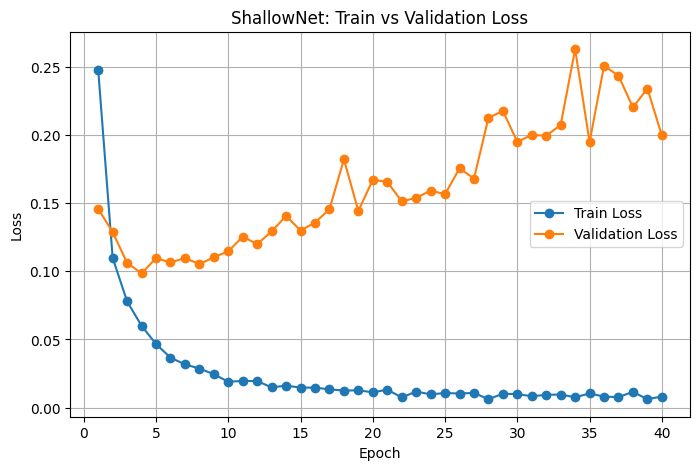

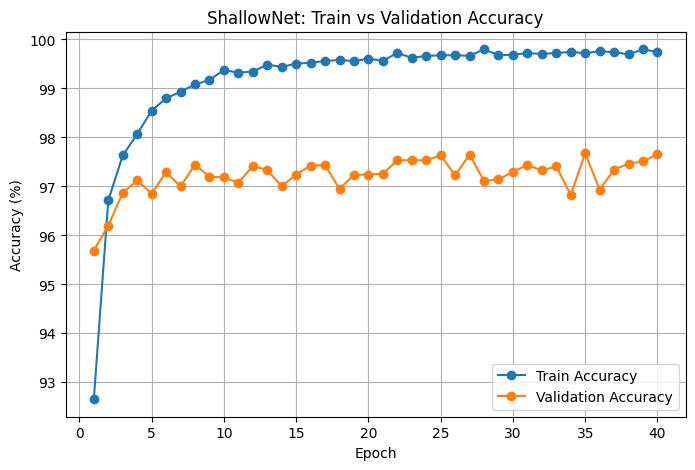

In [7]:
epochs = range(1, 41)
plt.figure(figsize=(8, 5))
plt.plot(epochs, t_loss1, marker='o', label='Train Loss')
plt.plot(epochs, v_loss1, marker='o', label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('ShallowNet: Train vs Validation Loss')
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(epochs, t_acc1, marker='o', label='Train Accuracy')
plt.plot(epochs, v_acc1, marker='o', label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.title('ShallowNet: Train vs Validation Accuracy')
plt.legend()
plt.grid(True)


# DEEP

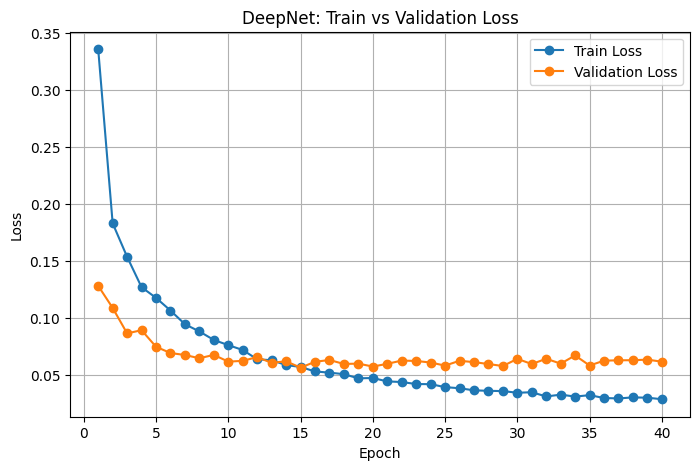

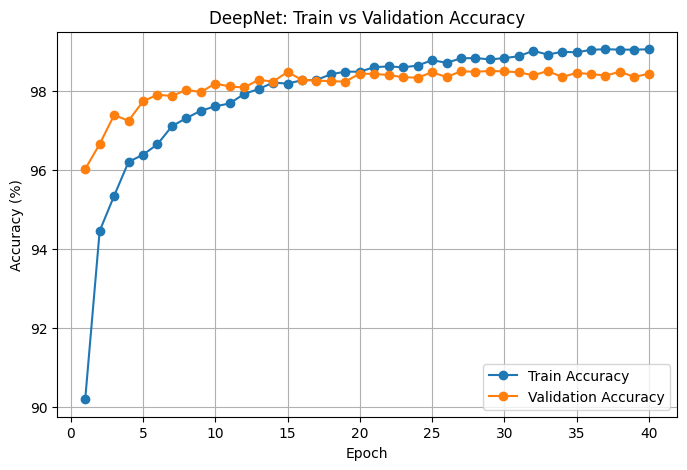

In [8]:
epochs = range(1, 41)
plt.figure(figsize=(8, 5))
plt.plot(epochs, t_loss2, marker='o', label='Train Loss')
plt.plot(epochs, v_loss2, marker='o', label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('DeepNet: Train vs Validation Loss')
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(epochs, t_acc2, marker='o', label='Train Accuracy')
plt.plot(epochs, v_acc2, marker='o', label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.title('DeepNet: Train vs Validation Accuracy')
plt.legend()
plt.grid(True)


In [ ]:
test_loader = make_loader(test_data, batch_size=256, shuffle=False, seed=SEED)

final_shallow_model = ShallowNet().to(device)
final_deep_model = DeepNet().to(device)

final_shallow_model.load_state_dict(torch.load('weights_shallow.pth', map_location=device))
final_shallow_model.eval()

final_deep_model.load_state_dict(torch.load('weights_deep.pth', map_location=device))
final_deep_model.eval()

criterion = nn.CrossEntropyLoss()
test_loss_shallow, acc_shallow = evaluate(final_shallow_model, test_loader, criterion)
test_loss_deep, acc_deep = evaluate(final_deep_model, test_loader, criterion)

print("\nFINAL TEST ACCURACY")
print(f"ShallowNet: {acc_shallow:.2f}%")
print(f"DeepNet:    {acc_deep:.2f}%")


FINAL TEST ACCURACY
ShallowNet: 98.00%
DeepNet:    98.44%


### Conclusions 

A complete final interpretation is in file Task_1_C, where we also examine the training behavior of the deep model without regularization, so we can infer a final conclusion directly when we have all information available
